
CLOUD RESOURCE ALLOCATION USING SIMPY

Number of Tasks: 20
Number of VMs: 5

------------------------------
FCFS RESOURCE ALLOCATION
------------------------------
Task  0 --> VM 0
Task  1 --> VM 1
Task  2 --> VM 2
Task  3 --> VM 3
Task  4 --> VM 4
Task  5 --> VM 0
Task  6 --> VM 2
Task  7 --> VM 0
Task  8 --> VM 4
Task  9 --> VM 0
Task 10 --> VM 1
Task 11 --> VM 3
Task 12 --> VM 2
Task 13 --> VM 4
Task 14 --> VM 0
Task 15 --> VM 1
Task 16 --> VM 2
Task 17 --> VM 3
Task 18 --> VM 4
Task 19 --> VM 4

------------------------------
RANDOM RESOURCE ALLOCATION
------------------------------
Task  0 --> VM 1
Task  1 --> VM 2
Task  2 --> VM 4
Task  3 --> VM 2
Task  4 --> VM 1
Task  5 --> VM 2
Task  6 --> VM 4
Task  7 --> VM 3
Task  8 --> VM 3
Task  9 --> VM 3
Task 10 --> VM 0
Task 11 --> VM 4
Task 12 --> VM 2
Task 13 --> VM 4
Task 14 --> VM 1
Task 15 --> VM 1
Task 16 --> VM 3
Task 17 --> VM 1
Task 18 --> VM 0
Task 19 --> VM 0

GENETIC ALGORITHM RESULT
Best Fitness: 25
Best Allocation: [4, 3

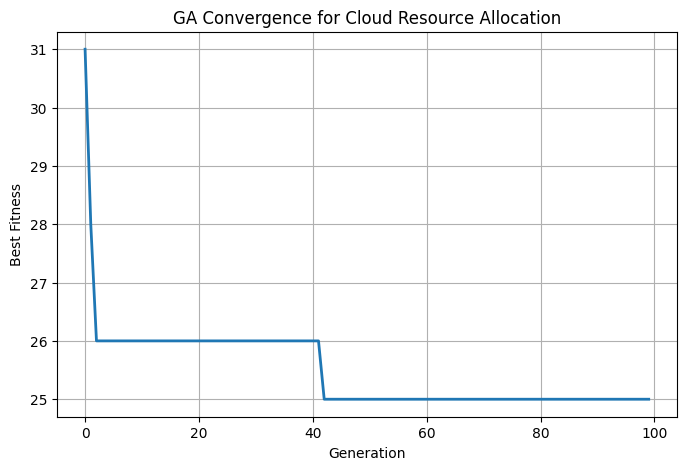

In [4]:
import simpy
import random
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# CLOUD CONFIGURATION
# ============================================================
NUM_VMS = 5
NUM_TASKS = 20
VM_CAPACITY = [10, 15, 20, 25, 30]  # CPU capacity of each VM

# ============================================================
# TASK CLASS
# ============================================================
class CloudTask:
    def __init__(self, task_id, cpu_required, execution_time):
        self.task_id = task_id
        self.cpu_required = cpu_required
        self.execution_time = execution_time
        self.arrival_time = 0
        self.start_time = None
        self.finish_time = None
        self.vm_id = None


# ============================================================
# VM CLASS
# ============================================================
class VirtualMachine:
    def __init__(self, vm_id, capacity):
        self.vm_id = vm_id
        self.capacity = capacity
        self.available_time = 0
        self.busy_time = 0

        # SimPy resource
        self.resource = simpy.Resource(
            simpy.Environment(),
            capacity=1
        )


# ============================================================
# GENERATE CLOUD TASKS
# ============================================================
def generate_tasks():
    tasks = []
    random.seed(10)

    for i in range(NUM_TASKS):
        cpu_required = random.randint(1, 10)
        execution_time = random.randint(2, 10)

        task = CloudTask(
            i,
            cpu_required,
            execution_time
        )

        tasks.append(task)

    return tasks


# ============================================================
# GENETIC ALGORITHM
# ============================================================
class GeneticAlgorithm:
    def __init__(self, tasks, vm_capacity):
        self.tasks = tasks
        self.vm_capacity = vm_capacity
        self.num_tasks = len(tasks)
        self.num_vms = len(vm_capacity)
        self.population_size = 50
        self.generations = 100
        self.mutation_rate = 0.1

    # --------------------------------------------------------
    # CREATE CHROMOSOME
    # --------------------------------------------------------
    def create_chromosome(self):
        chromosome = []

        for task in self.tasks:
            # Select a VM randomly
            vm = random.randint(
                0,
                self.num_vms - 1
            )
            chromosome.append(vm)

        return chromosome

    # --------------------------------------------------------
    # INITIAL POPULATION
    # --------------------------------------------------------
    def create_population(self):
        return [
            self.create_chromosome()
            for _ in range(self.population_size)
        ]

    # --------------------------------------------------------
    # FITNESS FUNCTION
    # --------------------------------------------------------
    def fitness(self, chromosome):
        vm_time = [0] * self.num_vms
        penalty = 0

        for task, vm_id in zip(
            self.tasks,
            chromosome
        ):
            # Check CPU capacity
            if task.cpu_required > self.vm_capacity[vm_id]:
                penalty += 1000

            vm_time[vm_id] += task.execution_time

        makespan = max(vm_time)

        # Smaller makespan = better solution
        fitness_value = makespan + penalty

        return fitness_value

    # --------------------------------------------------------
    # SELECTION
    # --------------------------------------------------------
    def selection(self, population):
        population.sort(
            key=lambda chromosome:
            self.fitness(chromosome)
        )

        return population[:10]

    # --------------------------------------------------------
    # CROSSOVER
    # --------------------------------------------------------
    def crossover(self, parent1, parent2):
        point = random.randint(
            1,
            self.num_tasks - 1
        )

        child1 = (
            parent1[:point]
            + parent2[point:]
        )

        child2 = (
            parent2[:point]
            + parent1[point:]
        )

        return child1, child2

    # --------------------------------------------------------
    # MUTATION
    # --------------------------------------------------------
    def mutation(self, chromosome):
        for i in range(self.num_tasks):
            if random.random() < self.mutation_rate:
                chromosome[i] = random.randint(
                    0,
                    self.num_vms - 1
                )

        return chromosome

    # --------------------------------------------------------
    # RUN GA
    # --------------------------------------------------------
    def run(self):
        population = self.create_population()
        best_solution = None
        best_fitness = float("inf")
        fitness_history = []

        for generation in range(
            self.generations
        ):
            population = self.selection(
                population
            )

            current_best = population[0]
            current_fitness = self.fitness(
                current_best
            )

            if current_fitness < best_fitness:
                best_fitness = current_fitness
                best_solution = current_best.copy()

            fitness_history.append(
                best_fitness
            )

            new_population = []

            # Elitism
            new_population.extend(
                population
            )

            while len(new_population) < self.population_size:
                parent1 = random.choice(
                    population
                )

                parent2 = random.choice(
                    population
                )

                child1, child2 = self.crossover(
                    parent1,
                    parent2
                )

                child1 = self.mutation(
                    child1
                )

                child2 = self.mutation(
                    child2
                )

                new_population.append(
                    child1
                )

                if len(new_population) < self.population_size:
                    new_population.append(
                        child2
                    )

            population = new_population

        print("\n==============================")
        print("GENETIC ALGORITHM RESULT")
        print("==============================")

        print(
            "Best Fitness:",
            best_fitness
        )

        print(
            "Best Allocation:",
            best_solution
        )

        return best_solution, fitness_history


# ============================================================
# SIMPY CLOUD SIMULATION
# ============================================================
def simulate_cloud(
    tasks,
    allocation,
    vm_capacity
):
    env = simpy.Environment()

    # Create VMs
    vms = [
        simpy.Resource(
            env,
            capacity=1
        )
        for _ in vm_capacity
    ]

    results = []

    # --------------------------------------------------------
    # TASK PROCESS
    # --------------------------------------------------------
    def execute_task(task):
        vm_id = allocation[
            task.task_id
        ]

        vm = vms[vm_id]
        arrival_time = env.now

        with vm.request() as request:
            yield request

            start_time = env.now
            waiting_time = (
                start_time
                - arrival_time
            )

            # Simulate execution
            yield env.timeout(
                task.execution_time
            )

            finish_time = env.now

            results.append({
                "task": task.task_id,
                "vm": vm_id,
                "arrival": arrival_time,
                "start": start_time,
                "finish": finish_time,
                "waiting": waiting_time,
                "execution": task.execution_time
            })

    # --------------------------------------------------------
    # SUBMIT TASKS
    # --------------------------------------------------------
    for task in tasks:
        env.process(
            execute_task(task)
        )

    # Run simulation
    env.run()

    return results


# ============================================================
# FCFS RESOURCE ALLOCATION
# ============================================================
def fcfs_allocation(tasks, vm_capacity):
    allocation = []
    vm_load = [
        0
        for _ in vm_capacity
    ]

    for task in tasks:
        # Select VM with minimum load
        vm = min(
            range(len(vm_capacity)),
            key=lambda i:
            vm_load[i]
        )

        allocation.append(vm)
        vm_load[vm] += (
            task.execution_time
        )

    return allocation


# ============================================================
# RANDOM RESOURCE ALLOCATION
# ============================================================
def random_allocation(tasks, vm_capacity):
    return [
        random.randint(
            0,
            len(vm_capacity) - 1
        )
        for _ in tasks
    ]


# ============================================================
# PERFORMANCE ANALYSIS
# ============================================================
def calculate_metrics(results):
    makespan = max(
        r["finish"]
        for r in results
    )

    average_waiting = np.mean(
        [
            r["waiting"]
            for r in results
        ]
    )

    total_execution = sum(
        r["execution"]
        for r in results
    )

    return (
        makespan,
        average_waiting,
        total_execution
    )


# ============================================================
# DISPLAY ALLOCATION
# ============================================================
def display_allocation(
    algorithm,
    allocation
):
    print("\n------------------------------")
    print(
        algorithm,
        "RESOURCE ALLOCATION"
    )
    print("------------------------------")

    for task_id, vm_id in enumerate(
        allocation
    ):
        print(
            f"Task {task_id:2d}"
            f" --> VM {vm_id}"
        )


# ============================================================
# MAIN PROGRAM
# ============================================================
def main():
    print(
        "\nCLOUD RESOURCE ALLOCATION "
        "USING SIMPY"
    )

    # Generate tasks
    tasks = generate_tasks()

    print(
        "\nNumber of Tasks:",
        len(tasks)
    )

    print(
        "Number of VMs:",
        NUM_VMS
    )

    # --------------------------------------------------------
    # FCFS
    # --------------------------------------------------------
    fcfs = fcfs_allocation(
        tasks,
        VM_CAPACITY
    )

    display_allocation(
        "FCFS",
        fcfs
    )

    fcfs_results = simulate_cloud(
        tasks,
        fcfs,
        VM_CAPACITY
    )

    fcfs_metrics = calculate_metrics(
        fcfs_results
    )

    # --------------------------------------------------------
    # RANDOM
    # --------------------------------------------------------
    random_alloc = random_allocation(
        tasks,
        VM_CAPACITY
    )

    display_allocation(
        "RANDOM",
        random_alloc
    )

    random_results = simulate_cloud(
        tasks,
        random_alloc,
        VM_CAPACITY
    )

    random_metrics = calculate_metrics(
        random_results
    )

    # --------------------------------------------------------
    # GENETIC ALGORITHM
    # --------------------------------------------------------
    ga = GeneticAlgorithm(
        tasks,
        VM_CAPACITY
    )

    ga_allocation, history = ga.run()

    display_allocation(
        "GENETIC ALGORITHM",
        ga_allocation
    )

    ga_results = simulate_cloud(
        tasks,
        ga_allocation,
        VM_CAPACITY
    )

    ga_metrics = calculate_metrics(
        ga_results
    )

    # ========================================================
    # COMPARISON
    # ========================================================
    print("\n\n==============================================")
    print("ALGORITHM PERFORMANCE COMPARISON")
    print("==============================================")

    print(
        f"{'Algorithm':<20}"
        f"{'Makespan':<15}"
        f"{'Avg Waiting':<15}"
    )

    print("----------------------------------------------")

    print(
        f"{'FCFS':<20}"
        f"{fcfs_metrics[0]:<15.2f}"
        f"{fcfs_metrics[1]:<15.2f}"
    )

    print(
        f"{'Random':<20}"
        f"{random_metrics[0]:<15.2f}"
        f"{random_metrics[1]:<15.2f}"
    )

    print(
        f"{'Genetic Algorithm':<20}"
        f"{ga_metrics[0]:<15.2f}"
        f"{ga_metrics[1]:<15.2f}"
    )

    # ========================================================
    # GA CONVERGENCE GRAPH
    # ========================================================
    plt.figure(figsize=(8, 5))

    plt.plot(
        history,
        linewidth=2
    )

    plt.xlabel(
        "Generation"
    )

    plt.ylabel(
        "Best Fitness"
    )

    plt.title(
        "GA Convergence for Cloud Resource Allocation"
    )

    plt.grid(True)
    plt.show()


# ============================================================
# PROGRAM START
# ============================================================
if __name__ == "__main__":
    main()


CLOUD RESOURCE ALLOCATION USING BFO + SIMPY

Number of Tasks: 20
Number of VMs: 5
VM Capacities: [10, 15, 20, 25, 30]

TASK INFORMATION
------------------------------------
T0: CPU=10, Execution=2
T1: CPU=7, Execution=9
T2: CPU=10, Execution=2
T3: CPU=4, Execution=9
T4: CPU=8, Execution=6
T5: CPU=3, Execution=2
T6: CPU=9, Execution=9
T7: CPU=6, Execution=3
T8: CPU=4, Execution=7
T9: CPU=1, Execution=8
T10: CPU=3, Execution=7
T11: CPU=7, Execution=8
T12: CPU=5, Execution=6
T13: CPU=8, Execution=4
T14: CPU=5, Execution=7
T15: CPU=3, Execution=9
T16: CPU=4, Execution=9
T17: CPU=10, Execution=8
T18: CPU=1, Execution=2
T19: CPU=4, Execution=4

BFO OPTIMIZATION COMPLETED
Best Fitness: 25.2
Best Allocation: [0, 2, 0, 3, 1, 1, 3, 3, 2, 0, 1, 2, 4, 3, 1, 4, 4, 0, 1, 0]

BFO RESOURCE ALLOCATION
Task  0 --> VM 0
Task  1 --> VM 2
Task  2 --> VM 0
Task  3 --> VM 3
Task  4 --> VM 1
Task  5 --> VM 1
Task  6 --> VM 3
Task  7 --> VM 3
Task  8 --> VM 2
Task  9 --> VM 0
Task 10 --> VM 1
Task 11 --> VM 2

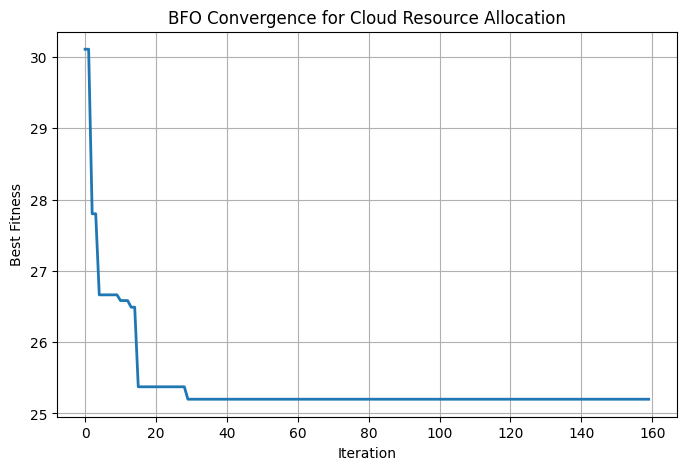

In [5]:
import simpy
import random
import numpy as np
import matplotlib.pyplot as plt

# ============================================================
# CLOUD CONFIGURATION
# ============================================================
NUM_VMS = 5
NUM_TASKS = 20
VM_CAPACITY = [10, 15, 20, 25, 30]

# ============================================================
# CLOUD TASK
# ============================================================
class CloudTask:
    def __init__(self, task_id, cpu_required, execution_time):
        self.task_id = task_id
        self.cpu_required = cpu_required
        self.execution_time = execution_time


# ============================================================
# GENERATE CLOUD TASKS
# ============================================================
def generate_tasks():
    random.seed(10)
    tasks = []

    for i in range(NUM_TASKS):
        cpu_required = random.randint(1, 10)
        execution_time = random.randint(2, 10)

        tasks.append(
            CloudTask(
                i,
                cpu_required,
                execution_time
            )
        )

    return tasks


# ============================================================
# BACTERIAL FORAGING OPTIMIZATION
# ============================================================
class BFO:
    def __init__(self, tasks, vm_capacity):
        self.tasks = tasks
        self.vm_capacity = vm_capacity
        self.num_tasks = len(tasks)
        self.num_vms = len(vm_capacity)

        # BFO parameters
        self.S = 30          # Number of bacteria
        self.Nc = 20         # Chemotactic steps
        self.Ns = 4          # Swimming length
        self.Nre = 4         # Reproduction steps
        self.Ned = 2         # Elimination-dispersal events
        self.Ped = 0.20      # Probability of elimination
        self.C = 1.0         # Step size

        self.population = []

    # ========================================================
    # CREATE RANDOM BACTERIUM
    # ========================================================
    def create_bacterium(self):
        return [
            random.randint(
                0,
                self.num_vms - 1
            )
            for _ in range(self.num_tasks)
        ]

    # ========================================================
    # INITIALIZE POPULATION
    # ========================================================
    def initialize_population(self):
        self.population = [
            self.create_bacterium()
            for _ in range(self.S)
        ]

    # ========================================================
    # FITNESS FUNCTION
    # ========================================================
    def fitness(self, solution):
        vm_load = [
            0
            for _ in range(self.num_vms)
        ]

        penalty = 0

        for task, vm_id in zip(
            self.tasks,
            solution
        ):
            # CPU capacity constraint
            if task.cpu_required > self.vm_capacity[vm_id]:
                penalty += 1000

            # Calculate workload
            vm_load[vm_id] += task.execution_time

        # Maximum VM workload
        makespan = max(vm_load)

        # Load imbalance
        average_load = np.mean(vm_load)
        imbalance = np.std(vm_load)

        # Final objective
        fitness = (
            makespan
            + 0.5 * imbalance
            + penalty
        )

        return fitness

    # ========================================================
    # RANDOM CHEMOTACTIC MOVE
    # ========================================================
    def tumble(self, bacterium):
        new_solution = bacterium.copy()

        task_id = random.randint(
            0,
            self.num_tasks - 1
        )

        new_vm = random.randint(
            0,
            self.num_vms - 1
        )

        new_solution[task_id] = new_vm

        return new_solution

    # ========================================================
    # SWIMMING
    # ========================================================
    def swim(
        self,
        bacterium,
        current_fitness
    ):
        best_solution = bacterium.copy()
        best_fitness = current_fitness

        for _ in range(self.Ns):
            new_solution = self.tumble(
                best_solution
            )

            new_fitness = self.fitness(
                new_solution
            )

            if new_fitness < best_fitness:
                best_solution = new_solution
                best_fitness = new_fitness
            else:
                break

        return (
            best_solution,
            best_fitness
        )

    # ========================================================
    # ELIMINATION AND DISPERSAL
    # ========================================================
    def elimination_dispersal(self):
        for i in range(self.S):
            if random.random() < self.Ped:
                self.population[i] = self.create_bacterium()

    # ========================================================
    # RUN BFO
    # ========================================================
    def run(self):
        self.initialize_population()

        best_solution = None
        best_fitness = float("inf")
        history = []

        # ====================================================
        # ELIMINATION-DISPERSAL LOOP
        # ====================================================
        for ed in range(self.Ned):

            # ================================================
            # REPRODUCTION LOOP
            # ================================================
            for reproduction in range(self.Nre):

                # ============================================
                # CHEMOTAXIS
                # ============================================
                for chemotaxis in range(self.Nc):
                    fitness_values = []

                    for i in range(self.S):
                        bacterium = self.population[i]

                        current_fitness = self.fitness(
                            bacterium
                        )

                        # Update global best
                        if current_fitness < best_fitness:
                            best_fitness = current_fitness
                            best_solution = bacterium.copy()

                        # ====================================
                        # TUMBLING
                        # ====================================
                        new_solution = self.tumble(
                            bacterium
                        )

                        new_fitness = self.fitness(
                            new_solution
                        )

                        # ====================================
                        # ACCEPT IMPROVED SOLUTION
                        # ====================================
                        if new_fitness < current_fitness:
                            self.population[i] = new_solution
                            current_fitness = new_fitness

                        # ====================================
                        # SWIMMING
                        # ====================================
                        (
                            improved_solution,
                            improved_fitness
                        ) = self.swim(
                            self.population[i],
                            current_fitness
                        )

                        if improved_fitness < current_fitness:
                            self.population[i] = improved_solution
                            current_fitness = improved_fitness

                        fitness_values.append(
                            current_fitness
                        )

                    # Record best fitness
                    current_best = min(
                        fitness_values
                    )

                    if current_best < best_fitness:
                        best_fitness = current_best

                        index = fitness_values.index(
                            current_best
                        )

                        best_solution = self.population[
                            index
                        ].copy()

                    history.append(
                        best_fitness
                    )

                # =================================================
                # REPRODUCTION
                # =================================================
                ranked = sorted(
                    self.population,
                    key=self.fitness
                )

                # Calculate health
                health = []

                for bacterium in ranked:
                    health.append(
                        self.fitness(
                            bacterium
                        )
                    )

                # Keep best half
                half = self.S // 2
                survivors = ranked[:half]

                # Reproduce
                new_population = []

                for bacterium in survivors:
                    new_population.append(
                        bacterium.copy()
                    )

                    new_population.append(
                        bacterium.copy()
                    )

                self.population = new_population[:self.S]

            # =================================================
            # ELIMINATION / DISPERSAL
            # =================================================
            self.elimination_dispersal()

        print("\n====================================")
        print(
            "BFO OPTIMIZATION COMPLETED"
        )
        print("====================================")

        print(
            "Best Fitness:",
            best_fitness
        )

        print(
            "Best Allocation:",
            best_solution
        )

        return (
            best_solution,
            history
        )


# ============================================================
# SIMPY CLOUD SIMULATION
# ============================================================
def simulate_cloud(
    tasks,
    allocation,
    vm_capacity
):
    env = simpy.Environment()

    # Create one SimPy resource for each VM
    vms = [
        simpy.Resource(
            env,
            capacity=1
        )
        for _ in vm_capacity
    ]

    results = []

    # ========================================================
    # TASK EXECUTION PROCESS
    # ========================================================
    def execute_task(task):
        vm_id = allocation[
            task.task_id
        ]

        vm = vms[vm_id]
        arrival_time = env.now

        with vm.request() as request:
            yield request

            start_time = env.now

            waiting_time = (
                start_time
                - arrival_time
            )

            # Execute task
            yield env.timeout(
                task.execution_time
            )

            finish_time = env.now

            results.append({
                "task": task.task_id,
                "vm": vm_id,
                "start": start_time,
                "finish": finish_time,
                "waiting": waiting_time,
                "execution": task.execution_time
            })

    # ========================================================
    # SUBMIT TASKS
    # ========================================================
    for task in tasks:
        env.process(
            execute_task(task)
        )

    # Run simulation
    env.run()

    return results


# ============================================================
# PERFORMANCE METRICS
# ============================================================
def calculate_metrics(results):
    makespan = max(
        r["finish"]
        for r in results
    )

    average_waiting = np.mean(
        [
            r["waiting"]
            for r in results
        ]
    )

    total_execution = sum(
        r["execution"]
        for r in results
    )

    return (
        makespan,
        average_waiting,
        total_execution
    )


# ============================================================
# DISPLAY ALLOCATION
# ============================================================
def display_allocation(
    allocation
):
    print("\n====================================")
    print(
        "BFO RESOURCE ALLOCATION"
    )
    print("====================================")

    for task_id, vm_id in enumerate(
        allocation
    ):
        print(
            f"Task {task_id:2d}"
            f" --> VM {vm_id}"
        )


# ============================================================
# MAIN
# ============================================================
def main():
    print(
        "\nCLOUD RESOURCE ALLOCATION "
        "USING BFO + SIMPY"
    )

    # --------------------------------------------------------
    # Generate Tasks
    # --------------------------------------------------------
    tasks = generate_tasks()

    print(
        "\nNumber of Tasks:",
        len(tasks)
    )

    print(
        "Number of VMs:",
        NUM_VMS
    )

    print(
        "VM Capacities:",
        VM_CAPACITY
    )

    # --------------------------------------------------------
    # Display Tasks
    # --------------------------------------------------------
    print("\nTASK INFORMATION")
    print("------------------------------------")

    for task in tasks:
        print(
            f"T{task.task_id}: "
            f"CPU={task.cpu_required}, "
            f"Execution={task.execution_time}"
        )

    # --------------------------------------------------------
    # BFO
    # --------------------------------------------------------
    bfo = BFO(
        tasks,
        VM_CAPACITY
    )

    allocation, history = bfo.run()

    # --------------------------------------------------------
    # Display Allocation
    # --------------------------------------------------------
    display_allocation(
        allocation
    )

    # --------------------------------------------------------
    # SimPy Simulation
    # --------------------------------------------------------
    results = simulate_cloud(
        tasks,
        allocation,
        VM_CAPACITY
    )

    # --------------------------------------------------------
    # Metrics
    # --------------------------------------------------------
    (
        makespan,
        average_waiting,
        total_execution
    ) = calculate_metrics(
        results
    )

    print("\n====================================")
    print(
        "SIMULATION RESULTS"
    )
    print("====================================")

    print(
        "Makespan:",
        makespan
    )

    print(
        "Average Waiting Time:",
        round(
            average_waiting,
            2
        )
    )

    print(
        "Total Execution Time:",
        total_execution
    )

    # --------------------------------------------------------
    # Task Results
    # --------------------------------------------------------
    print("\nTASK EXECUTION")
    print("------------------------------------")

    for result in sorted(
        results,
        key=lambda x: x["task"]
    ):
        print(
            f"Task {result['task']:2d} | "
            f"VM {result['vm']} | "
            f"Start {result['start']:5.1f} | "
            f"Finish {result['finish']:5.1f} | "
            f"Wait {result['waiting']:5.1f}"
        )

    # --------------------------------------------------------
    # BFO Convergence Graph
    # --------------------------------------------------------
    plt.figure(
        figsize=(8, 5)
    )

    plt.plot(
        history,
        linewidth=2
    )

    plt.xlabel(
        "Iteration"
    )

    plt.ylabel(
        "Best Fitness"
    )

    plt.title(
        "BFO Convergence for "
        "Cloud Resource Allocation"
    )

    plt.grid(True)
    plt.show()


# ============================================================
# PROGRAM START
# ============================================================
if __name__ == "__main__":
    main()